Supervised learning:
- classification  
  - binary classification  
- regression  
  - "analogic"
  
Feature = predictor variable = independent variable (x axis)  
Target variable = dependent variable = response variable (y axis)

Requirements:  
- no missing values
- data in numeric values 
- data in pandas dataframe / numpy array  

Scikit-learn syntax:

```python
from sklearn.module import Model
model = Model()
model.fit(X, y)
predictions = model.predict(X_new)
print(predictions)
```

,height,weight
0,170,57


,height,weight,class,height2,weight2,eucl,bmi
0,167,51,u,9,36,6.71,18.29
1,182,62,n,144,25,13.00,18.72
2,176,69,n,36,144,13.42,22.28
3,173,64,n,9,49,7.62,21.38
4,172,65,n,4,64,8.25,21.97
5,174,56,u,16,1,4.12,18.50
6,169,58,n,1,1,1.41,20.31
7,173,57,n,9,0,3.00,19.05
8,170,55,n,0,4,2.00,19.03


result: ['u']


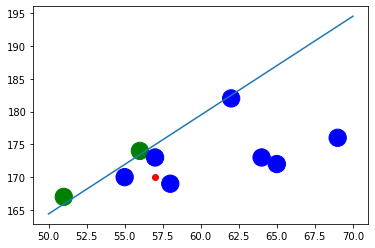

In [1]:
# KNN - K nearest neigbors
# https://www.youtube.com/watch?v=4HKqjENq9OU

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
pd.options.display.float_format = lambda x: f'{x:,.2f}'
df = pd.DataFrame(
    data = {
        'height':[167, 182,176 ,173, 172, 174 ,169, 173, 170],
        'weight':[51 , 62 , 69 ,64 , 65 , 56  ,58  ,57 , 55],
        'class':['u', 'n', 'n', 'n', 'n', 'u', 'n', 'n', 'n'],

    }
)



df_target = pd.DataFrame(
    data = {
        'height':[170],
        'weight':[57],
    }
)

display(df_target)

plt.scatter(x = df_target['weight'], y = df_target['height'], c = 'red')
plt.scatter(x = df['weight'], y = df['height'], c = df['class'].map({'n':'blue','u':'green'}), s = 300)
plt.plot([50,70], [(50/18.5)**(1/2)*100, (70/18.5)**(1/2)*100])

df_knn = (
    df
    .assign(height2 =  (df['height'] - df_target['height'].values)**2)
    .assign(weight2 =  (df['weight'] - df_target['weight'].values)**2)
    .assign(eucl =  lambda x: (x['height2'] + x['weight2'])**(1/2))
    .assign(bmi = lambda x: x['weight']/((x['height']/100))**2)
)

display(df_knn)

# get knn of 3
print('result:', df_knn.head(6).sort_values('eucl')['class'].head(3).value_counts().head(1).index.values)
# -> it is normal!

## CAREFUL!!! KNN would be 'underweight' if you only considered the first 7 rows!

In [24]:
# with sklearn knn, it is always 'n'... go figure
# Import KNeighborsClassifier
from sklearn.neighbors import KNeighborsClassifier


# Create arrays for the features and the target variable
y = df["class"].values
X = df[['weight','height']].values

dic = {}
for i in range(1,len(df)):
    # Create a KNN classifier with 6 neighbors
    knn = KNeighborsClassifier(n_neighbors = i)

    # Fit the classifier to the data
    knn.fit(X, y)

    print(f'for {i} neighbors, class is:', knn.predict(df_target.values))
    dic[i] = knn.fit(X,y)

dic


for 1 neighbors, class is: ['n']
for 2 neighbors, class is: ['n']
for 3 neighbors, class is: ['n']
for 4 neighbors, class is: ['n']
for 5 neighbors, class is: ['n']
for 6 neighbors, class is: ['n']
for 7 neighbors, class is: ['n']
for 8 neighbors, class is: ['n']


{1: KNeighborsClassifier(n_neighbors=1),
 2: KNeighborsClassifier(n_neighbors=2),
 3: KNeighborsClassifier(n_neighbors=3),
 4: KNeighborsClassifier(n_neighbors=4),
 5: KNeighborsClassifier(),
 6: KNeighborsClassifier(n_neighbors=6),
 7: KNeighborsClassifier(n_neighbors=7),
 8: KNeighborsClassifier(n_neighbors=8)}

,account_length,customer_service_calls,churn
0,128,1,0
1,107,1,0
2,137,0,0
3,84,2,0
4,75,3,0
...,...,...,...
3328,192,2,0
3329,68,3,0
3330,28,2,0
3331,184,2,0


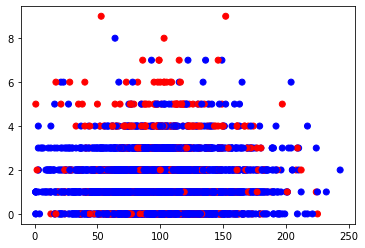

In [25]:
# datacamp exercise (finally!)

churn_df = pd.read_csv('tables/telecom_churn_clean.csv').drop('Unnamed: 0', axis = 1)

plt.scatter(x = churn_df['account_length'], y = churn_df['customer_service_calls'], c = churn_df['churn'].map({0:'blue',1:'red'}))

churn_df[['account_length','customer_service_calls','churn']]

In [26]:
X_new = np.array([[30.0, 17.5],
                  [107.0, 24.1],
                  [213.0, 10.9]])


Text(0, 0.5, 'customer service calls')

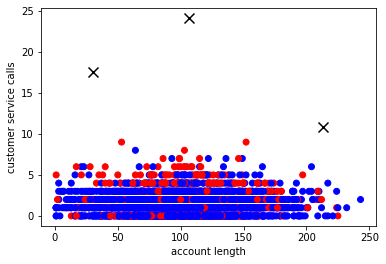

In [27]:
plt.scatter(x = churn_df['account_length'], y = churn_df['customer_service_calls'], c = churn_df['churn'].map({0:'blue',1:'red'}))
plt.scatter(x = [i[0] for i in X_new], y = [i[1] for i in X_new], marker = 'x', s = 100, c = 'k')
plt.xlabel('account length')
plt.ylabel('customer service calls')

In [28]:
churn_df[['account_length','customer_service_calls','churn']].agg(['mean','median'])

,account_length,customer_service_calls,churn
mean,101.06,1.56,0.14
median,101.00,1.00,0.00


In [29]:
X_new

array([[ 30. ,  17.5],
       [107. ,  24.1],
       [213. ,  10.9]])

In [31]:
# trying manual KNN with churn data
# -> it works!

df_c = churn_df[['account_length','customer_service_calls','churn']].copy()

for n,i in enumerate(X_new):
    df_c[f'target_{n}'] = str(i)
    df_c[f'eucl_{n}'] = (((df_c['account_length'] - i[0])**2) + ((df_c['customer_service_calls'] - i[1])**2))**(1/2)

display(df_c.head())
    
(
    df_c.sort_values('eucl_0').head(6)['churn'].mode()[0],
    df_c.sort_values('eucl_1').head(6)['churn'].mode()[0],
    df_c.sort_values('eucl_2').head(6)['churn'].mode()[0],

)
    

,account_length,customer_service_calls,churn,target_0,eucl_0,target_1,eucl_1,target_2,eucl_2
0,128,1,0,[30. 17.5],99.38,[107. 24.1],31.22,[213. 10.9],85.57
1,107,1,0,[30. 17.5],78.75,[107. 24.1],23.10,[213. 10.9],106.46
2,137,0,0,[30. 17.5],108.42,[107. 24.1],38.48,[213. 10.9],76.78
3,84,2,0,[30. 17.5],56.18,[107. 24.1],31.90,[213. 10.9],129.31
4,75,3,0,[30. 17.5],47.28,[107. 24.1],38.33,[213. 10.9],138.23


(0, 1, 0)

Measuring model performance

Accuracy:
correct predictions / total observations


Split data
- Training set -> Fit / train classifier on training set
- Test set         
- Training + test set: Calculate accuracy using test set

```python
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state=21, stratify = y)

knn = KNeighborsClassifier(n_neighbors=6)
knn.fit(X_train, y_train)
print(knn.score(X_test, y_test))
```

Underfitting and Overfitting:
- Thinking about the underweight/normal weight example:
  - if k = 1, you only look at the most similar value = the smallest boundary possible (only closer than 1.41 = Overfitting
  - if k = len(df), you look at all the values = the most frequent value will be selected = Underfitting!
  
Model complexity and over/underfitting:
```python
train_accuracies = {}
test_accuracies = {}
neighbors = np.arange(1,26)
for neighbor in neighbors:
    knn = KNeighborsClassifier(n_neighbors = neighbor)
    knn.fit(X_train, y_train)
    train_accuracies[neighbor] = knn.score(X_train, y_train)
    test_accuracies[neighbor] = knn.score(X_test, y_test)
plt.title('KNN: varying number of Neighbors')
plt.plot(neighbors, train_accuracies.values(), label = 'training accuracy')
plt.plot(neighbors, test_accuracies.values(), label = 'test accuracy')
```


In [57]:
import sklearn
from sklearn.neighbors import KNeighborsClassifier

df = pd.DataFrame(
    data = {
        'height':[167, 182,176 ,173, 172, 174 ,169, 173, 170],
        'weight':[51 , 62 , 69 ,64 , 65 , 56  ,58  ,57 , 55],
        'class':['u', 'n', 'n', 'n', 'n', 'u', 'n', 'n', 'n'],

    }
)
dic = {}
for i in range(1, len(df)):
    
    knn = KNeighborsClassifier(n_neighbors = i)
    knn.fit(df[['height','weight']], df['class'])

    results = knn.predict(df[['height','weight']])
    dic[i] = sum(results == df['class'].values)/len(df)
    dic[i] = round(dic[i],2)

display(dic)
# as the n increases, the accuracy decreases





{1: 1.0, 2: 0.78, 3: 0.78, 4: 0.78, 5: 0.78, 6: 0.78, 7: 0.78, 8: 0.78}

In [59]:
from sklearn.model_selection import train_test_split

X = churn_df.drop('churn', axis = 1).values
y = churn_df['churn'].values

X_train, X_test, y_train, y_test = (
    train_test_split(
        X, y, 
        test_size = 0.2, 
        random_state = 42, 
        stratify = y))

knn = KNeighborsClassifier(n_neighbors = 5)

knn.fit(X_train, y_train)

knn.score(X_test, y_test)

0.8740629685157422

In [184]:
# separate 20% of the table (1 table -> 2 tables)
X_train = churn_df.sample(frac = 0.2, random_state = 42)
X_test = churn_df.loc[set(churn_df.index) - set(X_train.index)]
print(X_test.shape, X_train.shape)

# separate the churn column of each part (2 -> 4)
y_train = X_train[['churn']]
y_test = X_test[['churn']]
y_test['prediction'] = np.nan
y_train = y_train.copy().reset_index()
y_test = y_test.copy().reset_index()

X_train = X_train.drop('churn', axis = 1)
X_test = X_test.drop('churn', axis = 1)
display(X_train.shape, y_train.shape)

# for each row of the 80% table, 
#  -do the euclidian distance for each value on the table with 20% of the rows
lala = y_train.copy()
dic_results = {}

## For the test part
for i in range(len(X_test)):
#     print(X_test.iloc[i,:].values)    
    lala['lele'] = (((X_train.values - X_test.iloc[i,:].values)**2).sum(axis = 1)**(1/2))
# #  -collect the mode for the churn
    for j in range(1,15):
        y_test.loc[i,f'prediction_{j}'] = lala.sort_values('lele')['churn'].head(j).mode()[0]
# #  - save the mode as a new column on the churn table with the 80%
#     dic_results[f'round_{}'] = (y_test['churn'] == y_test['prediction']).sum()/y_test.shape[0]

## For the train part
for i in range(len(X_train)):
#     print(X_test.iloc[i,:].values)    
    lala['lele'] = (((X_train.values - X_train.iloc[i,:].values)**2).sum(axis = 1)**(1/2))
# #  -collect the mode for the churn
    for j in range(1,15):
        y_train.loc[i,f'prediction_{j}'] = lala.sort_values('lele')['churn'].head(j).mode()[0]
# #  - save the mode as a new column on the churn table with the 80%
#     dic_results[f'round_{}'] = (y_test['churn'] == y_test['prediction']).sum()/y_test.shape[0]


(2666, 19) (667, 19)


/tmp/ipykernel_4181/2971934579.py:3: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  X_test = churn_df.loc[set(churn_df.index) - set(X_train.index)]
/tmp/ipykernel_4181/2971934579.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  y_test['prediction'] = np.nan


(667, 18)

(667, 2)

In [189]:
test_knn_values = {x: (y_test['churn'] == y_test[f'prediction_{x}']).sum()/y_test.shape[0] for x in range(1, 15)}
test_knn_values

{1: 0.8184546136534133,
 2: 0.8653413353338335,
 3: 0.8593398349587397,
 4: 0.8668417104276069,
 5: 0.8690922730682671,
 6: 0.8717179294823706,
 7: 0.8743435858964741,
 8: 0.8717179294823706,
 9: 0.8735933983495874,
 10: 0.8713428357089272,
 11: 0.873218304576144,
 12: 0.8724681170292573,
 13: 0.8743435858964741,
 14: 0.872093023255814}

In [190]:
train_knn_values = {x: (y_train['churn'] == y_train[f'prediction_{x}']).sum()/y_train.shape[0] for x in range(1, 15)}
train_knn_values

{1: 1.0,
 2: 0.9085457271364318,
 3: 0.9085457271364318,
 4: 0.8935532233883059,
 5: 0.8920539730134932,
 6: 0.8920539730134932,
 7: 0.889055472263868,
 8: 0.8830584707646177,
 9: 0.8845577211394303,
 10: 0.8830584707646177,
 11: 0.8845577211394303,
 12: 0.881559220389805,
 13: 0.8860569715142429,
 14: 0.8770614692653673}

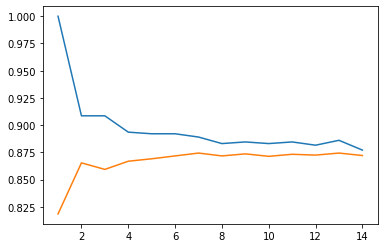

In [194]:
# the bigger the n you use to get the mode:
# -> the better is the training
# -> the worse is the testing
plt.plot(train_knn_values.keys(), train_knn_values.values())
plt.plot(test_knn_values.keys(), test_knn_values.values())

In [117]:
(y_test['churn'] == y_test['prediction']).sum()/y_test.shape[0]

0.8567141785446362

Regression

```python
X = diabetes_df.drop('glucose', axis = 1).values
y = diabetes_df['glucose'].values

X_bmi = X[:,3]
X_bmi = X_bmi.reshape(-1,1)

from sklearn.linear_model import LinearRegression
reg = LinearRegression()
reg.fit(X_bmi, y)
predictions = reg.predict(X_bmi)
```

Dataset: sales_df - advertising campaign


In [61]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt

sales_df = pd.read_csv('tables/advertising_and_sales_clean.csv')

X = sales_df['radio'].values
y = sales_df['sales']

X = X.reshape(-1,1)

print(X.shape, y.shape)

(4546, 1) (4546,)


In [62]:
sales_df.corr()

,tv,radio,social_media,sales
tv,1.00,0.87,0.53,1.00
radio,0.87,1.00,0.61,0.87
social_media,0.53,0.61,1.00,0.53
sales,1.00,0.87,0.53,1.00


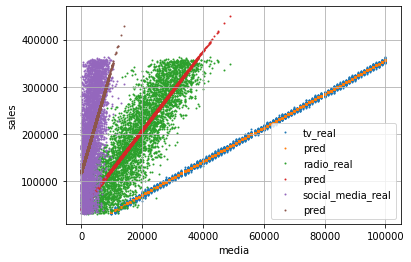

In [63]:
from sklearn.linear_model import LinearRegression
reg = LinearRegression()

lr_df = sales_df.copy()

for col in ['tv','radio','social_media']:
    lr_df[col] = reg.fit(sales_df[[col]], sales_df['sales']).predict(sales_df[[col]])
    plt.scatter(sales_df[col], sales_df['sales'], label = f'{col}_real', s = 1)
    plt.scatter(sales_df[col], lr_df[col], label = 'pred', s = 1)
plt.legend()
plt.xlabel('media')
plt.ylabel('sales')
plt.grid()

In [64]:
reg.intercept_, reg.coef_

(118672.57173913241, array([22.18786317]))

Regression:

y = ax + b

y = target
x = single feature
a,b = parameters/coefficients of the model - slope, intercept

How do we choose a and b?
- Define an error function for any given line
- Choose the line that minimizes the error function  
Error function = loss function = cost function

Distance between the 'curve' and the y values = residual

Remember: deviations is from mean; residuals is from regression curve!

RSS = Residual Sum of Squares 
```python
RSS = [(y - ŷ)**2 for y, ŷ in zip(yaxis, prediction)] 
```

Type of linear regression that minimizes RSS: Ordinary Least Squares (OLS)
(MMQ? Método dos mínimos quadrados?)

Higher dimensions:
y = a1x1 + a2x2 + b

-> Multiplar linear regression


```python
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)
# sklearn is doing OLS under the hood
reg_all = LinearRegression()
reg_all.fit(X_train, y_train)
y_pred = reg_all.predict(X_test)
```
R-squared (r2) - quantifies the variance in target values
- values range from 0 to 1  
R2 is the one that is highly influenced by the slope: the lower, lower the R2  
R2 is also the squared value of ... sth (pearson correlation perhaps?)

Calculating Rsquared:
```python
reg_all.score(X_test, y_test)
```

MSE = Mean Squared Error = RMSE/n

```python
from sklearn.metrics import mean_squared_error
mean_squared_error(y_test, y_pred, squared = False)
```

In [67]:
# Create X and y arrays
from sklearn.model_selection import train_test_split

X = sales_df.drop(["sales",'influencer'], axis=1).values
y = sales_df["sales"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Instantiate the model
reg = LinearRegression()

# Fit the model to the data
reg.fit(X_train,y_train)

# Make predictions
y_pred = reg.predict(X_test)
y_pred = [round(x,2) for x in y_pred]
print("Predictions: {}, Actual Values: {}".format(y_pred[:2], y_test[:2]))

Predictions: [53176.66, 70996.2], Actual Values: [55261.28 67574.9 ]


In [66]:
# Import mean_squared_error
from sklearn.metrics import mean_squared_error

# Compute R-squared
r_squared = reg.score(X_test, y_test)

# Compute RMSE
rmse = mean_squared_error(y_test, y_pred, squared=False)

# Print the metrics
print("R^2: {}".format(r_squared))
print("RMSE: {}".format(rmse))

R^2: 0.9990152104759368
RMSE: 2944.4331996001
